<a href="https://colab.research.google.com/github/Keerthireddy2503/EDA/blob/main/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [182]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [183]:
df=pd.read_csv("/content/housing_prices_regression.csv")
df

,num_bedrooms,year_built,zipcode_dup,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
0,2.0,2021.0,110002.0,110002.0,1075,Ys,H20000,NaN,3.0,NaN
1,3.0,1954.0,560001.0,560001.0,1482,Ye,H20001,o,1.5,293483.53
2,2.0,1991.0,560002.0,560002.0,1689,No,H20002,No,2.5,179736.91
3,3.0,1956.0,NaN,NaN,1415,Yes,H20003,es,NaN,462700.04
4,NaN,1991.0,560001.0,560001.0,1765,No,H20004,NO,1.0,272214.40
...,...,...,...,...,...,...,...,...,...,...
255,2.0,1950.0,110001.0,110001.0,1402,No,H20012,NO,2.0,NaN
256,2.0,1991.0,560002.0,560002.0,1689,No,H20002,No,2.5,179736.91
257,3.0,1954.0,560001.0,560001.0,1482,Ye,H20001,o,1.5,293483.53
258,3.0,1974.0,110003.0,110003.0,1239,YES,NaN,NaN,2.0,701046.18


In [184]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_bedrooms   238 non-null    float64
 1   year_built     241 non-null    float64
 2   zipcode_dup    230 non-null    float64
 3   zipcode        230 non-null    float64
 4   size_sqft      237 non-null    object 
 5   has_garage     237 non-null    object 
 6   id             230 non-null    object 
 7   has_garden     232 non-null    object 
 8   num_bathrooms  221 non-null    float64
 9   sale_price     238 non-null    float64
dtypes: float64(6), object(4)
memory usage: 20.4+ KB


In [185]:
df["num_bedrooms"].unique()

array([ 2.,  3., nan,  5.,  4.,  1.])

In [186]:
df["num_bedrooms"]=df["num_bedrooms"].fillna(df["num_bedrooms"].mean()).round().astype(int)
df["sale_price"]=df["sale_price"].fillna(df["sale_price"].median()).round().astype(int)
df["num_bathrooms"]=df["num_bathrooms"].fillna(df["num_bathrooms"].mean()).round().astype(int)
df["has_garage"]=df["has_garage"].fillna(df["has_garage"].mode()[0])
df["has_garden"]=df["has_garage"].fillna(df["has_garden"].mode()[0])
df["zipcode"]=df["zipcode"].fillna(df["zipcode"].mode()[0]).round().astype(int)
df


,num_bedrooms,year_built,zipcode_dup,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
0,2,2021.0,110002.0,110002,1075,Ys,H20000,Ys,3,444708
1,3,1954.0,560001.0,560001,1482,Ye,H20001,Ye,2,293484
2,2,1991.0,560002.0,560002,1689,No,H20002,No,2,179737
3,3,1956.0,NaN,110001,1415,Yes,H20003,Yes,2,462700
4,3,1991.0,560001.0,560001,1765,No,H20004,No,1,272214
...,...,...,...,...,...,...,...,...,...,...
255,2,1950.0,110001.0,110001,1402,No,H20012,No,2,444708
256,2,1991.0,560002.0,560002,1689,No,H20002,No,2,179737
257,3,1954.0,560001.0,560001,1482,Ye,H20001,Ye,2,293484
258,3,1974.0,110003.0,110003,1239,YES,NaN,YES,2,701046


In [187]:
df["num_bedrooms"].unique()

array([2, 3, 5, 4, 1])

In [188]:
df=df.drop(columns=["zipcode_dup"])

In [189]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_bedrooms   260 non-null    int64  
 1   year_built     241 non-null    float64
 2   zipcode        260 non-null    int64  
 3   size_sqft      237 non-null    object 
 4   has_garage     260 non-null    object 
 5   id             230 non-null    object 
 6   has_garden     260 non-null    object 
 7   num_bathrooms  260 non-null    int64  
 8   sale_price     260 non-null    int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 18.4+ KB


to_numeric() converts object datatype into int eventhough it has nan values

In [190]:
df["size_sqft"]=df["size_sqft"].replace('unknown',float('nan'))
df["size_sqft"]=pd.to_numeric(df["size_sqft"])

In [191]:
df["size_sqft"]=df["size_sqft"].fillna(df["size_sqft"].median()).round().astype(int)
df["year_built"]=df["year_built"].fillna(df["year_built"].mean().round().astype(int))
df

,num_bedrooms,year_built,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
0,2,2021.0,110002,1075,Ys,H20000,Ys,3,444708
1,3,1954.0,560001,1482,Ye,H20001,Ye,2,293484
2,2,1991.0,560002,1689,No,H20002,No,2,179737
3,3,1956.0,110001,1415,Yes,H20003,Yes,2,462700
4,3,1991.0,560001,1765,No,H20004,No,1,272214
...,...,...,...,...,...,...,...,...,...
255,2,1950.0,110001,1402,No,H20012,No,2,444708
256,2,1991.0,560002,1689,No,H20002,No,2,179737
257,3,1954.0,560001,1482,Ye,H20001,Ye,2,293484
258,3,1974.0,110003,1239,YES,NaN,YES,2,701046


In [192]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_bedrooms   260 non-null    int64  
 1   year_built     260 non-null    float64
 2   zipcode        260 non-null    int64  
 3   size_sqft      260 non-null    int64  
 4   has_garage     260 non-null    object 
 5   id             230 non-null    object 
 6   has_garden     260 non-null    object 
 7   num_bathrooms  260 non-null    int64  
 8   sale_price     260 non-null    int64  
dtypes: float64(1), int64(5), object(3)
memory usage: 18.4+ KB


In [193]:
df["id"].isnull().sum()


np.int64(30)

In [194]:
id

<function id(obj, /)>

In [195]:
df=df.drop(columns=['id'])

In [196]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_bedrooms   260 non-null    int64  
 1   year_built     260 non-null    float64
 2   zipcode        260 non-null    int64  
 3   size_sqft      260 non-null    int64  
 4   has_garage     260 non-null    object 
 5   has_garden     260 non-null    object 
 6   num_bathrooms  260 non-null    int64  
 7   sale_price     260 non-null    int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 16.4+ KB


we can find the number of unique values through unique()

In [197]:
df["has_garage"].unique()

array(['Ys', 'Ye', 'No', 'Yes', 'N', 'YES', 'o', 'es', 'NO'], dtype=object)

In [198]:
df["has_garden"].unique()

array(['Ys', 'Ye', 'No', 'Yes', 'N', 'YES', 'o', 'es', 'NO'], dtype=object)

In [199]:
df['has_garage'] = df['has_garage'].replace({
    'Ys': 'Yes',
    'Ye': 'Yes',
    'es': 'Yes',
    'YES': 'Yes',
    'N': 'No',
    'o': 'No',
    'NO': 'No'
})
df['has_garden'] = df['has_garden'].replace({
    'Ys': 'Yes',
    'Ye': 'Yes',
    'es': 'Yes',
    'YES': 'Yes',
    'N': 'No',
    'o': 'No',
    'NO': 'No'
})

In [200]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_bedrooms   260 non-null    int64  
 1   year_built     260 non-null    float64
 2   zipcode        260 non-null    int64  
 3   size_sqft      260 non-null    int64  
 4   has_garage     260 non-null    object 
 5   has_garden     260 non-null    object 
 6   num_bathrooms  260 non-null    int64  
 7   sale_price     260 non-null    int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 16.4+ KB


In [201]:
df.head()

,num_bedrooms,year_built,zipcode,size_sqft,has_garage,has_garden,num_bathrooms,sale_price
0,2,2021.0,110002,1075,Yes,Yes,3,444708
1,3,1954.0,560001,1482,Yes,Yes,2,293484
2,2,1991.0,560002,1689,No,No,2,179737
3,3,1956.0,110001,1415,Yes,Yes,2,462700
4,3,1991.0,560001,1765,No,No,1,272214


In [202]:
df["size_sqft"].unique()

array([ 1075,  1482,  1689,  1415,  1765,  1177,  1901,  1549,  2118,
        2466,  1312,  1328,  1402,  1738,  2030,  1239,  1652,  1446,
        1747,  2104,  1404,   832,  1798,  1167,  1495,  1815,  1619,
        1459,  1270,   340,  1779,  1399,  2105,  1284,  1927,  1960,
        1412,  1977,  1278,  1729,  1749,  1367,  1937,  1450,  1272,
        2276,  1203,  2017,  1046,  1695,  2148,  1238,  1128,  1453,
        2166,  1146,   465,  1524,  1880,  1094,  1839,  1086,  1441,
        1801,  1573,  1986,  1690,  1212,  2107,  1763,   756,  1846,
        1271,  1579,  1903,  1280,   842,  2102,  1966,  1465,  1841,
        1352,  1539,  1442,  1368,  1644,  1017,  1626,  1033,  1708,
         749,  1852,  1735,  1466,  1633,  1568,   824,  1577,  1353,
        1218,  2494,  2001,  1040,  2083,   902,  1531,  1550,   990,
        1946,  2103,  1400,  2501,   935,  1536,  1291,  1703,  1449,
        1196,  1677,   819,  1720,  1422,  1502,  1828,  1973,  1488,
        1282,  1739,

In [203]:
import seaborn as sns

UNIVARIATE

BARCHART

Text(0, 0.5, 'number of houses')

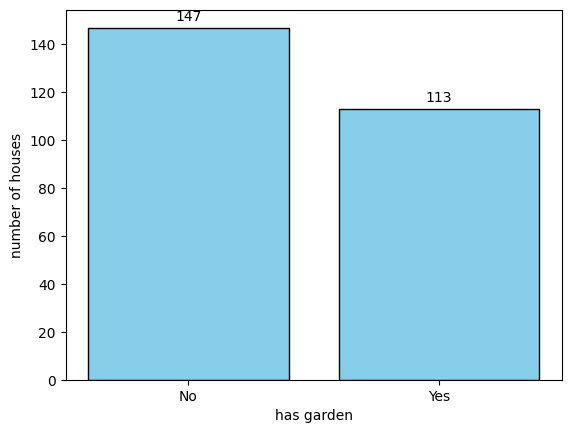

In [204]:
data =df["has_garden"].value_counts()
bar = plt.bar(data.index,data.values,color="skyblue",edgecolor="black")
plt.bar_label(bar,padding=3,label_type="edge")
plt.xlabel('has garden')
plt.ylabel('number of houses')

PIECHART

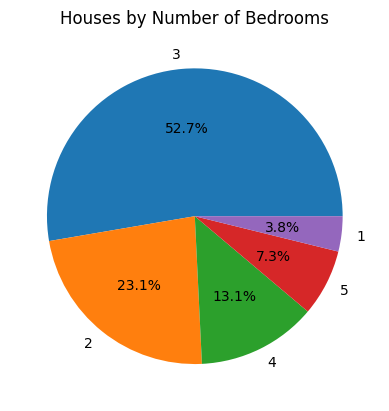

In [205]:
x = df['num_bedrooms'].value_counts()

plt.pie(x.values, labels=x.index, autopct='%1.1f%%')

plt.title('Houses by Number of Bedrooms')
plt.show()

HISTOGRAM

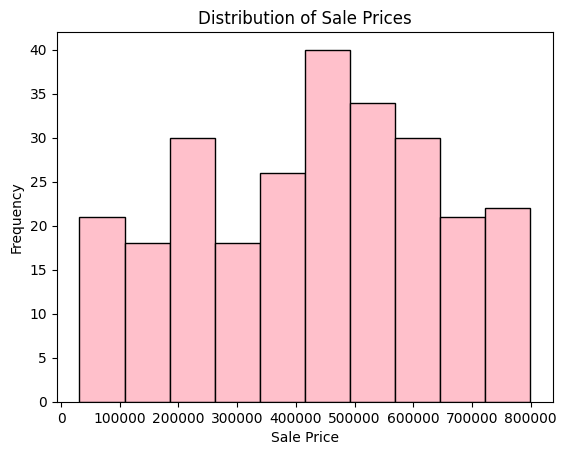

In [206]:

plt.hist(df['sale_price'], bins=10,color="pink",edgecolor="black")

plt.title('Distribution of Sale Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')
plt.show()

COUNTPLOT

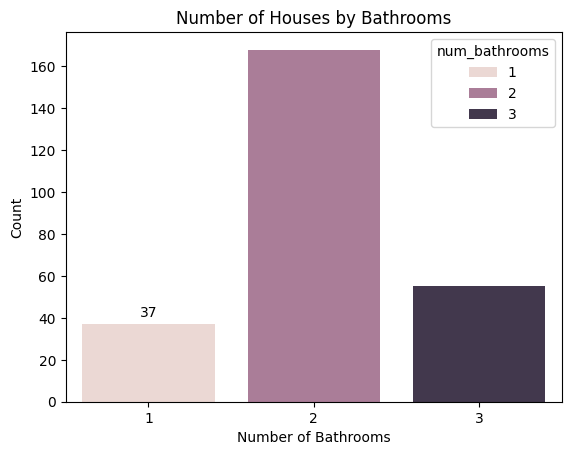

In [207]:
count=sns.countplot(data=df, x='num_bathrooms',hue='num_bathrooms',alpha=0.9)
plt.bar_label(count.containers[0],padding=3,label_type="edge")

plt.title('Number of Houses by Bathrooms')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Count')
plt.show()

BIVARIATE

BOXPLOT

<Axes: xlabel='size_sqft'>

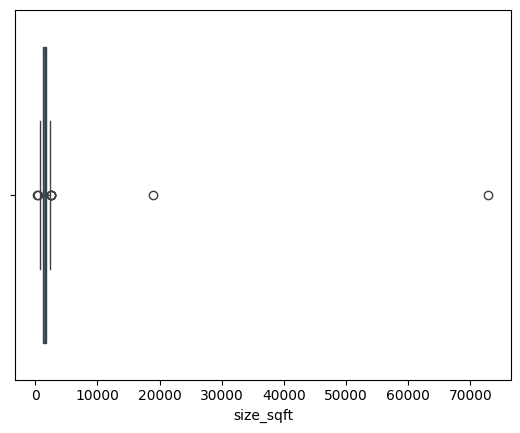

In [208]:
sns.boxplot(x=df["size_sqft"])


SCATTERPLOT

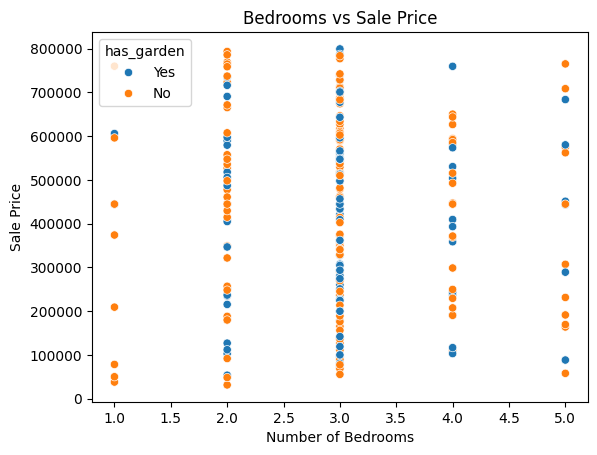

In [211]:
sns.scatterplot(data=df, x='num_bedrooms', y='sale_price',hue="has_garden")

plt.title('Bedrooms vs Sale Price')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Sale Price')
plt.show()

COUNTPLOT

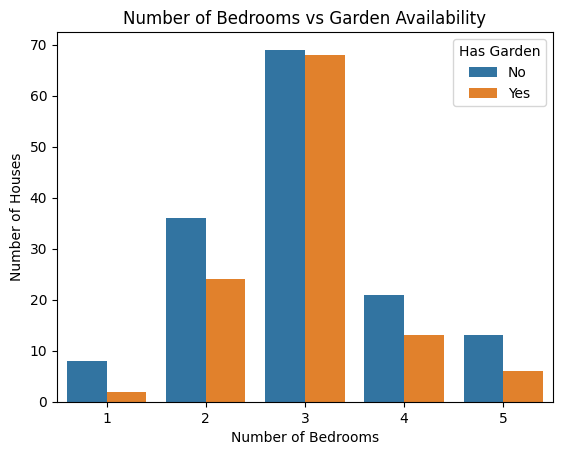

In [212]:
sns.countplot(data=df, x='num_bedrooms', hue='has_garden')

plt.title('Number of Bedrooms vs Garden Availability')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Number of Houses')
plt.legend(title='Has Garden')
plt.show()

MULTIVARIATE

PAIRPLOT

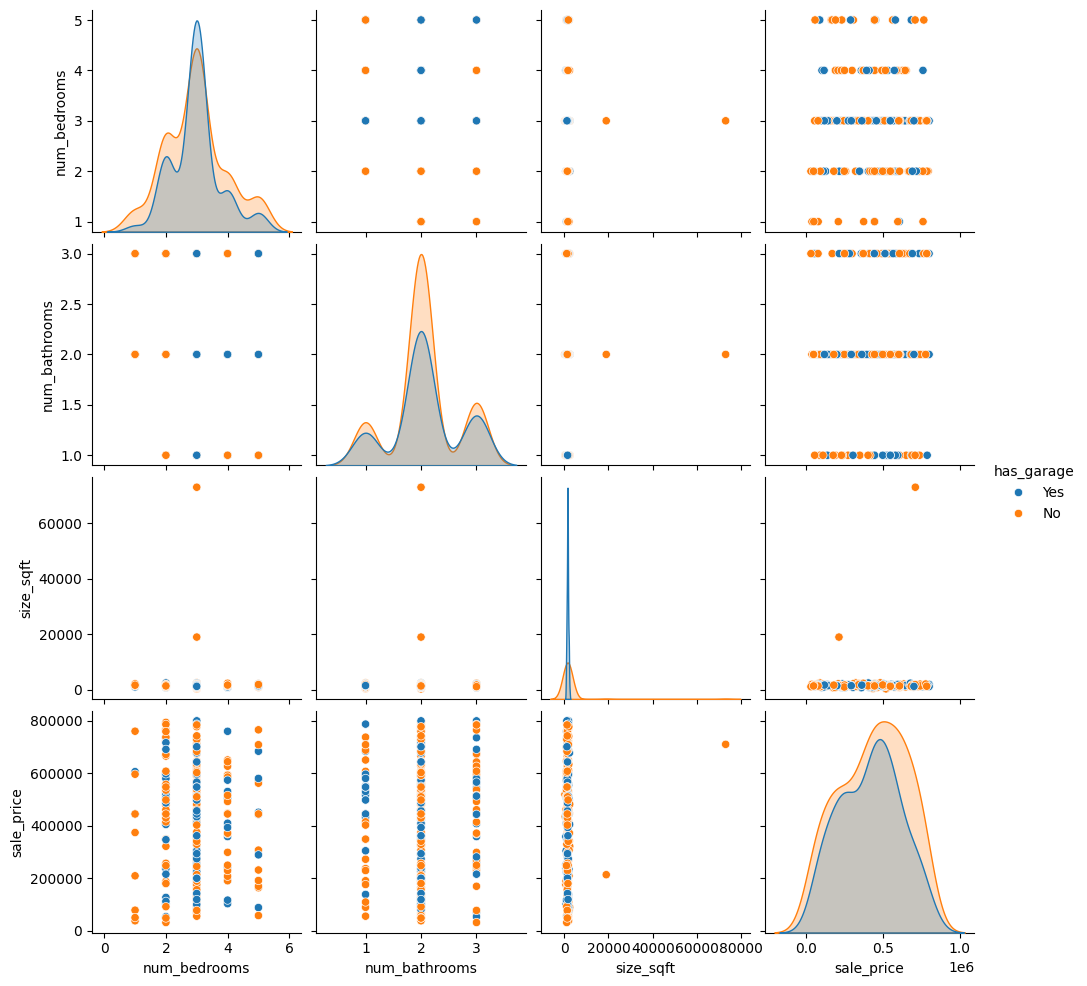

In [213]:
sns.pairplot(
    df,
    vars=['num_bedrooms', 'num_bathrooms',
          'size_sqft', 'sale_price'],
    hue='has_garage'
)

plt.show()

HEATMAP

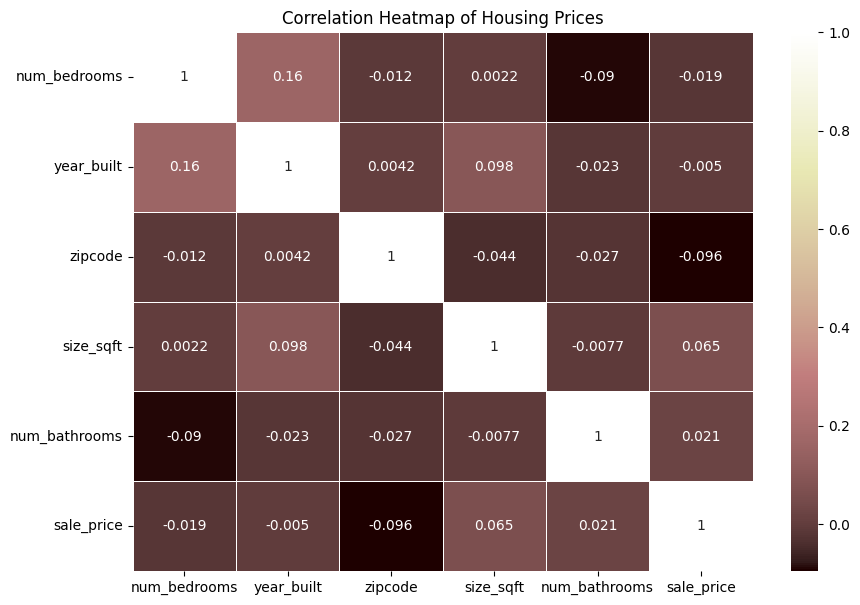

In [230]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(corr, annot=True, cmap='pink', linewidths=0.5)

plt.title('Correlation Heatmap of Housing Prices')
plt.show()